# CNN-Based Weapon-in-Hand Detection System for School CCTV
Classes: harmless_object, melee, ranged, student

**C7: Image size: 224x224**

3 Conv2D (32, 64, 128) + 3 MaxPooling2D, Dense 128, relu / softmax, **224x224**, batch 32, 4 epochs, adam

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
# Construct an instance of ImageDataGenerator class
# rescale = 1./255 normalizes the pixel values from 0-255 to 0-1
train_datagen = ImageDataGenerator(rescale = 1./255)
test_datagen = ImageDataGenerator(rescale = 1./255)

In [3]:
# Use flow_from_directory to take the path and generate batches of data
train_iterator = train_datagen.flow_from_directory(
    'dataset/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

test_iterator = test_datagen.flow_from_directory(
    'dataset/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

Found 15803 images belonging to 4 classes.
Found 880 images belonging to 4 classes.


In [4]:
# Defining the sequential model for weapon-in-hand classification
model = keras.Sequential()

# Convolution and Pooling Layers
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Conv2D(128, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

# Core Layers
model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu'))

# Output layer: 4 nodes with softmax (harmless_object, melee, ranged, student)
model.add(layers.Dense(4, activation='softmax'))

D:\Eztel71\Documents\Projects\Weapons_CNN\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
# Compile and fit the model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

history = model.fit(train_iterator, validation_data=test_iterator, epochs=4)

Epoch 1/4
494/494 ━━━━━━━━━━━━━━━━━━━━ 176s 355ms/step - accuracy: 0.4696 - loss: 1.1755 - val_accuracy: 0.5989 - val_loss: 0.9924
Epoch 2/4
494/494 ━━━━━━━━━━━━━━━━━━━━ 175s 355ms/step - accuracy: 0.6410 - loss: 0.8789 - val_accuracy: 0.6466 - val_loss: 0.9036
Epoch 3/4
494/494 ━━━━━━━━━━━━━━━━━━━━ 175s 354ms/step - accuracy: 0.7792 - loss: 0.5688 - val_accuracy: 0.6545 - val_loss: 0.9950
Epoch 4/4
494/494 ━━━━━━━━━━━━━━━━━━━━ 175s 354ms/step - accuracy: 0.9032 - loss: 0.2629 - val_accuracy: 0.6364 - val_loss: 1.2905


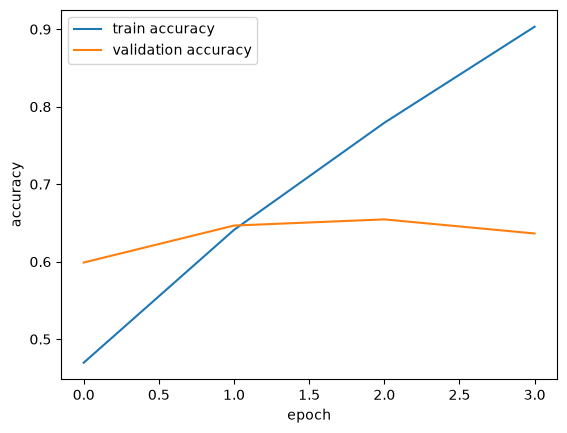

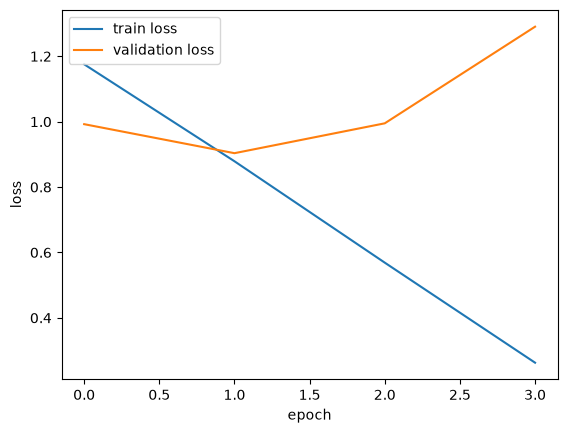

In [6]:
# Plot training vs validation accuracy and loss per epoch
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()

In [7]:
# Evaluating the Model using test data
model.evaluate(test_iterator)

28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step - accuracy: 0.6364 - loss: 1.2905


[1.2904609441757202, 0.6363636255264282]

In [8]:
# Saving Model
model.save('WeaponCNN_C7.h5')

In [9]:
# get the class labels from iterator
labels = train_iterator.class_indices
print(labels)

{'harmless_object': 0, 'melee': 1, 'ranged': 2, 'student': 3}


## Prediction

In [10]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import matplotlib.pyplot as plt
import numpy as np

In [11]:
# load the saved model
model = load_model('WeaponCNN_C7.h5')

# class labels from the iterator
labels = ['harmless_object', 'melee', 'ranged', 'student']

# TYPICAL PHOTOS TEST
Photos from `dataset/test/` in the most common style of each class (not used in training)

## student_0035.jpg
Actual: student

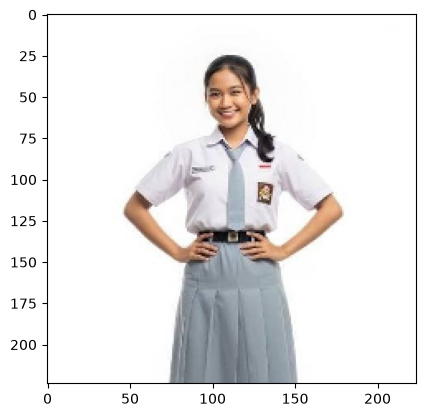

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
[[0.43008274 0.37738755 0.00770084 0.18482888]]
harmless_object


In [12]:
# load an image for prediction
img = load_img('dataset/test/student/student_0035.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## student_0232.jpg
Actual: student

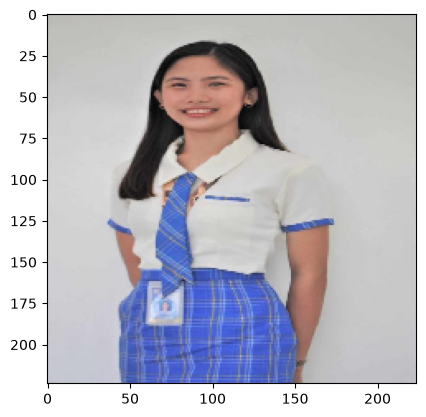

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
[[1.2142463e-04 6.2245896e-08 1.1265961e-06 9.9987733e-01]]
student


In [13]:
# load an image for prediction
img = load_img('dataset/test/student/student_0232.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_0302.jpg
Actual: harmless_object

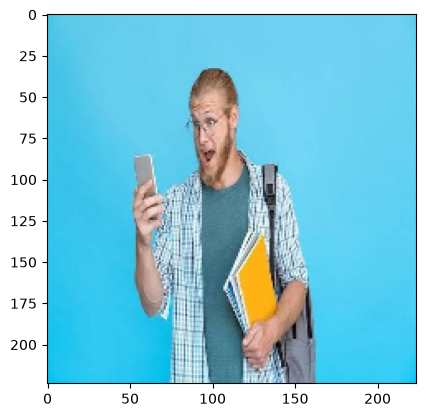

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
[[0.60367274 0.05578214 0.02918638 0.31135878]]
harmless_object


In [14]:
# load an image for prediction
img = load_img('dataset/test/harmless_object/harmless_object_0302.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_0321.jpg
Actual: harmless_object

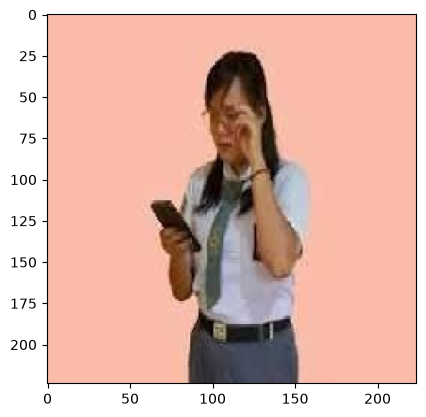

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
[[0.17513044 0.00544449 0.00700445 0.81242055]]
student


In [15]:
# load an image for prediction
img = load_img('dataset/test/harmless_object/harmless_object_0321.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_0107.jpg
Actual: melee

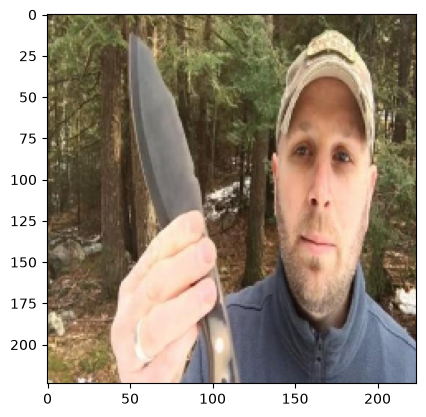

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
[[1.1156518e-03 9.9660313e-01 2.2786572e-03 2.4727140e-06]]
melee
ALERT: melee weapon detected, confidence 0.99660313


In [16]:
# load an image for prediction
img = load_img('dataset/test/melee/melee_0107.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_0155.jpg
Actual: melee

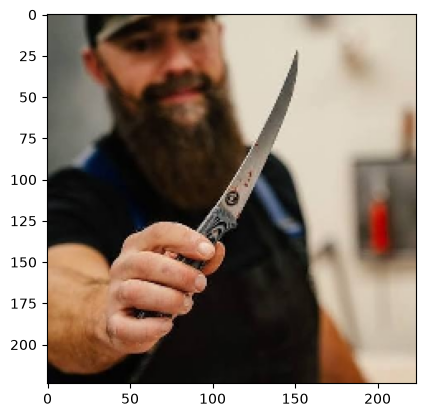

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
[[1.0389362e-01 4.6839115e-01 4.2769951e-01 1.5823123e-05]]
melee
ALERT: melee weapon detected, confidence 0.46839115


In [17]:
# load an image for prediction
img = load_img('dataset/test/melee/melee_0155.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_0103.jpg
Actual: ranged

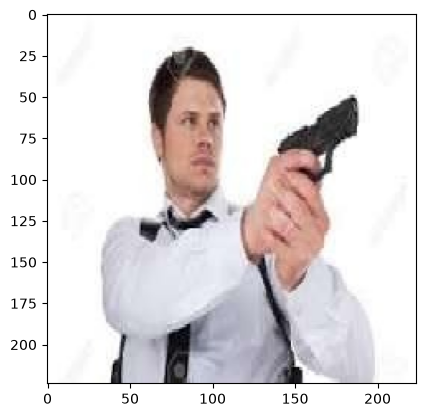

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
[[0.0416319  0.07871708 0.8763097  0.00334129]]
ranged
ALERT: ranged weapon detected, confidence 0.8763097


In [18]:
# load an image for prediction
img = load_img('dataset/test/ranged/ranged_0103.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_0139.jpg
Actual: ranged

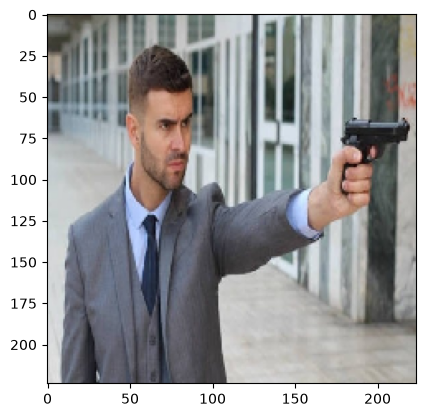

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
[[0.29438543 0.03920639 0.58276814 0.08364006]]
ranged
ALERT: ranged weapon detected, confidence 0.58276814


In [19]:
# load an image for prediction
img = load_img('dataset/test/ranged/ranged_0139.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

# OUR PHOTOS TEST
Our own photos from `my_photos_test/` (not used in training)

## student_test1.jpg
Actual: student

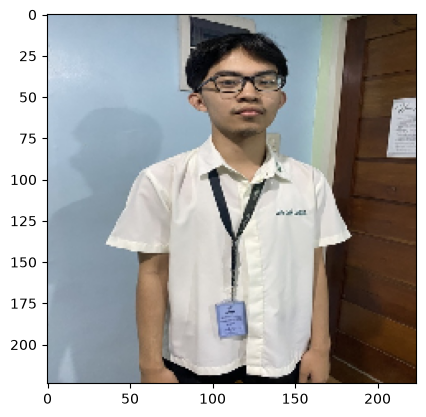

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
[[8.7306071e-03 4.9410543e-01 1.1911847e-04 4.9704486e-01]]
student


In [20]:
# load an image for prediction
img = load_img('my_photos_test/student_test1.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## student_test2.jpg
Actual: student

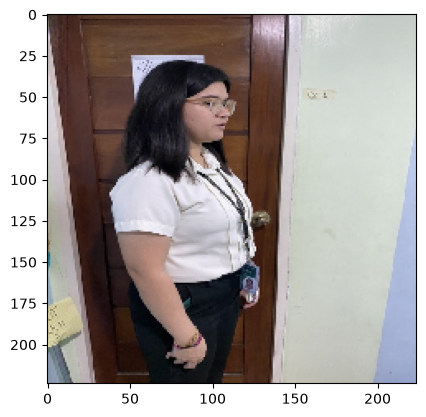

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
[[1.2919449e-04 1.3753043e-02 1.6841212e-05 9.8610097e-01]]
student


In [21]:
# load an image for prediction
img = load_img('my_photos_test/student_test2.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_test1.jpg
Actual: harmless_object

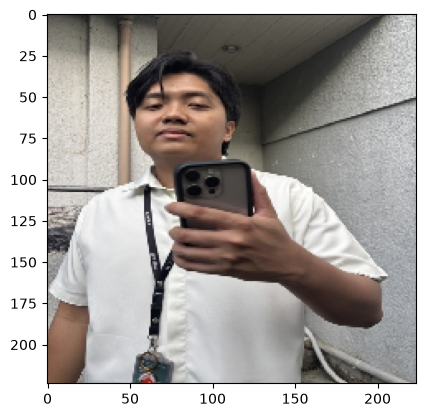

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
[[0.9784641  0.00323091 0.00344343 0.01486149]]
harmless_object


In [22]:
# load an image for prediction
img = load_img('my_photos_test/harmless_object_test1.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## harmless_object_test2.jpg
Actual: harmless_object

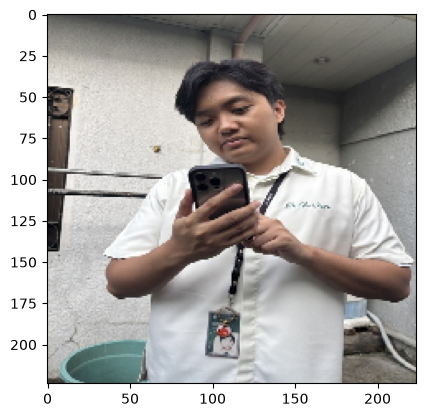

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
[[0.49937072 0.12081891 0.3614675  0.01834295]]
harmless_object


In [23]:
# load an image for prediction
img = load_img('my_photos_test/harmless_object_test2.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_test1.jpg
Actual: melee

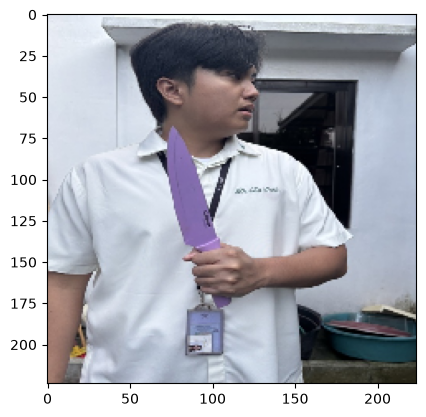

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
[[2.9502846e-03 3.1433299e-02 7.6868437e-04 9.6484774e-01]]
student


In [24]:
# load an image for prediction
img = load_img('my_photos_test/melee_test1.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## melee_test2.jpg
Actual: melee

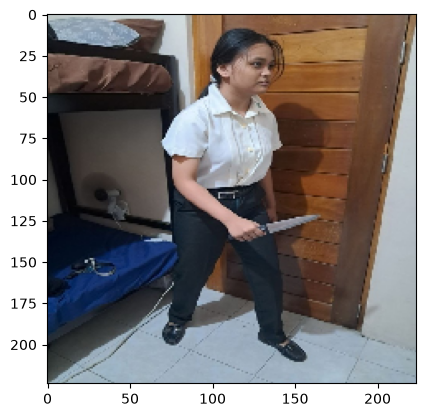

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
[[0.12037358 0.8438274  0.02446547 0.01133357]]
melee
ALERT: melee weapon detected, confidence 0.8438274


In [25]:
# load an image for prediction
img = load_img('my_photos_test/melee_test2.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_test1.jpg
Actual: ranged

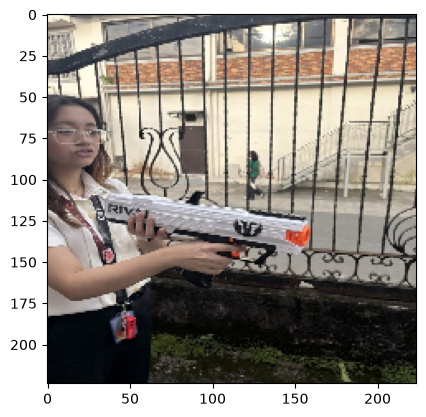

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
[[2.1848404e-03 4.6475393e-01 5.3284991e-01 2.1136229e-04]]
ranged
ALERT: ranged weapon detected, confidence 0.5328499


In [26]:
# load an image for prediction
img = load_img('my_photos_test/ranged_test1.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

## ranged_test2.jpg
Actual: ranged

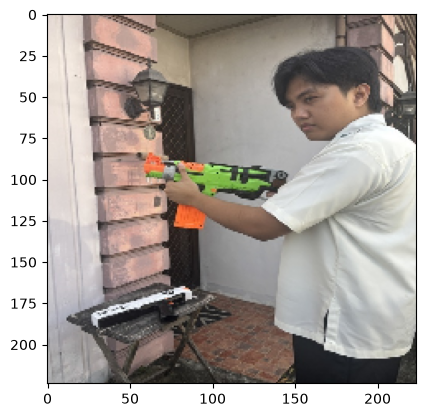

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
[[2.5554717e-04 6.1701420e-03 9.9336433e-01 2.1003465e-04]]
ranged
ALERT: ranged weapon detected, confidence 0.99336433


In [27]:
# load an image for prediction
img = load_img('my_photos_test/ranged_test2.jpg', target_size=(224, 224))
plt.imshow(img)
plt.show()

# convert img to array and add dimension
img = img_to_array(img)
img = img.reshape(1, 224, 224, 3)
img = img / 255

# getting the prediction
result = model.predict(img)
print(result)
confidence = np.max(result)
result = np.argmax(result)

if result == 0:
    print(labels[0])
elif result == 1:
    print(labels[1])
    print('ALERT: melee weapon detected, confidence', confidence)
elif result == 2:
    print(labels[2])
    print('ALERT: ranged weapon detected, confidence', confidence)
elif result == 3:
    print(labels[3])

# Conclusion

This part (C7) tested the C1 baseline CNN with one change: the input image size was increased from 150x150 to 224x224, with everything else held constant. The model was trained on 15,803 images and evaluated on 880 test images across four classes (harmless_object, melee, ranged, student).

**Overall performance:** _(fill in after running: training accuracy, test accuracy, test loss; did validation loss keep falling (underfitting) or start rising (overfitting)? compare with C1)_

**Sample predictions:** We also checked the saved model on 16 photos not used in training: 8 typical photos from `dataset/test/` and 8 of our own photos.

| Class | Typical photos | Our photos | Total |
|---|---|---|---|
| student | /2 | /2 | /4 |
| harmless_object | /2 | /2 | /4 |
| melee | /2 | /2 | /4 |
| ranged | /2 | /2 | /4 |
| All | /8 | /8 | /16 |

**Implication for the alert system:** _(how many of the 8 weapon photos triggered an alert? how many false alerts on the 8 non-weapon photos? confidence of the alerts)_

**Limitations:** _(fill in)_

**Recommendations:** _(fill in)_